# Part II — Airbnb NYC Listings Dataset Analysis

**Data Analytics I — Assignment 1**

This notebook analyses the `listings.csv` Airbnb NYC dataset covering price segmentation,
borough comparisons, location premiums, value-for-money, amenities, timeline effects,
and host portfolio analysis.

## 1. Libraries and Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
import ast

warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams.update({
    'figure.figsize': (10, 6), 'figure.dpi': 100,
    'axes.titlesize': 14, 'axes.labelsize': 12,
    'xtick.labelsize': 10, 'ytick.labelsize': 10,
    'legend.fontsize': 10, 'figure.titlesize': 16
})

COLORS = {
    'primary': '#2E86AB', 'secondary': '#A23B72', 'accent': '#F18F01',
    'success': '#2CA02C', 'danger': '#D32F2F', 'neutral': '#636363',
    'palette': ['#2E86AB', '#A23B72', '#F18F01', '#2CA02C', '#D32F2F',
                '#8E44AD', '#16A085', '#E74C3C']
}

print('Libraries loaded successfully.')

Libraries loaded successfully.


## 2. Dataset Loading and Inspection

In [2]:
listings_raw = pd.read_csv('listings.csv')
print(f'Shape: {listings_raw.shape[0]:,} rows × {listings_raw.shape[1]} columns')
print(f'\nColumn names and types:')
for i, col in enumerate(listings_raw.columns):
    print(f'  {i+1:2d}. {col} ({listings_raw[col].dtype})')

Shape: 30,259 rows × 90 columns

Column names and types:
   1. id (int64)
   2. listing_url (object)
   3. scrape_id (int64)
   4. last_scraped (object)
   5. source (object)
   6. name (object)
   7. description (object)
   8. neighborhood_overview (float64)
   9. picture_url (object)
  10. host_id (int64)
  11. host_url (object)
  12. host_profile_id (float64)
  13. host_profile_url (object)
  14. host_name (object)
  15. host_since (float64)
  16. hosts_time_as_user_years (float64)
  17. hosts_time_as_user_months (float64)
  18. hosts_time_as_host_years (float64)
  19. hosts_time_as_host_months (float64)
  20. host_location (object)
  21. host_about (object)
  22. host_response_time (float64)
  23. host_response_rate (float64)
  24. host_acceptance_rate (float64)
  25. host_is_superhost (object)
  26. host_thumbnail_url (float64)
  27. host_picture_url (object)
  28. host_neighbourhood (float64)
  29. host_listings_count (float64)
  30. host_total_listings_count (float64)
  31. host

In [3]:
# Missing values
missing = listings_raw.isnull().sum()
missing_pct = (missing / len(listings_raw) * 100).round(1)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing Count', ascending=False)
print(f'Columns with missing values: {len(missing_df)}')
missing_df.head(20)

Columns with missing values: 57


,Missing Count,Missing %
neighborhood_overview,30259,100.0
host_since,30259,100.0
host_neighbourhood,30259,100.0
host_verifications,30259,100.0
host_total_listings_count,30259,100.0
host_thumbnail_url,30259,100.0
host_response_time,30259,100.0
host_acceptance_rate,30259,100.0
host_response_rate,30259,100.0
calendar_updated,30259,100.0


In [4]:
print(f'Duplicate rows: {listings_raw.duplicated().sum()}')
print(f'Duplicate IDs:  {listings_raw["id"].duplicated().sum()}')

Duplicate rows: 0
Duplicate IDs:  0


## 3. Data Cleaning

In [5]:
listings = listings_raw.copy()

# --- Step 1: Parse price column ---
# Price stored as '$X.XX' string → float
listings['price_numeric'] = (
    listings['price']
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)
print(f'Price parsing: {listings["price_numeric"].notna().sum():,} valid, '
      f'{listings["price_numeric"].isna().sum():,} missing')

# --- Step 2: Handle invalid prices ---
zero_prices = (listings['price_numeric'] == 0).sum()
print(f'Price = 0 listings: {zero_prices}')
print(f'Price < 0 listings: {(listings["price_numeric"] < 0).sum()}')
listings.loc[listings['price_numeric'] == 0, 'price_numeric'] = np.nan
print(f'→ Set {zero_prices} zero-price listings to NaN (invalid).')

# --- Step 3: Standardize superhost ---
listings['is_superhost'] = listings['host_is_superhost'].map({'t': True, 'f': False})

# --- Step 4: Parse first_review ---
listings['first_review_dt'] = pd.to_datetime(listings['first_review'], errors='coerce')
reference_date = pd.to_datetime(listings['last_scraped']).max()
print(f'Reference date (latest scrape): {reference_date.date()}')
listings['years_since_first_review'] = (
    (reference_date - listings['first_review_dt']).dt.days / 365.25
).round(2)

# --- Step 5: Parse amenities ---
def parse_amenities(s):
    """Parse amenities JSON string to list."""
    if pd.isna(s):
        return []
    try:
        return ast.literal_eval(s)
    except (ValueError, SyntaxError):
        s = s.strip('[]')
        return [a.strip().strip('"').strip("'") for a in s.split(',') if a.strip()]

listings['amenities_list'] = listings['amenities'].apply(parse_amenities)
listings['amenity_count'] = listings['amenities_list'].apply(len)

# --- Step 6: price_per_guest ---
listings['price_per_guest'] = np.where(
    listings['accommodates'] > 0,
    listings['price_numeric'] / listings['accommodates'],
    np.nan
)

# --- Step 7: Borough alias ---
listings['borough'] = listings['neighbourhood_group_cleansed']

print(f'\nCleaned shape: {listings.shape}')
print(f'Valid price listings: {listings["price_numeric"].notna().sum():,}')

Price parsing: 21,515 valid, 8,744 missing
Price = 0 listings: 0
Price < 0 listings: 0
→ Set 0 zero-price listings to NaN (invalid).
Reference date (latest scrape): 2026-06-23

Cleaned shape: (30259, 98)
Valid price listings: 21,515


### Cleaning Decisions Summary

| Step | Action | Rationale |
|------|--------|-----------|
| 1 | Parsed `price` from `$X.XX` to float | Numeric operations require float type |
| 2 | Set zero-price to NaN | $0/night is not a valid listing price |
| 3 | Standardized `host_is_superhost` to boolean | Consistent True/False instead of 't'/'f' |
| 4 | Parsed `first_review` as datetime | Calculate listing age for maturity analysis |
| 5 | Parsed `amenities` from JSON string to list | Extract individual amenity indicators |
| 6 | Created `price_per_guest` | Key metric for value analysis (NaN if accommodates=0) |
| 7 | No rows dropped | All 30,259 listings retained; analysis filtered as needed |

In [6]:
# Working dataset = listings with valid prices
airbnb = listings[listings['price_numeric'].notna()].copy()
print(f'Working analysis dataset: {len(airbnb):,} listings with valid prices')
print(f'Excluded (missing price): {listings["price_numeric"].isna().sum():,} listings')
print(f'\nBorough distribution:')
print(airbnb['borough'].value_counts())
print(f'\nRoom type distribution:')
print(airbnb['room_type'].value_counts())
print(f'\nPrice summary:')
print(airbnb['price_numeric'].describe().round(2))

Working analysis dataset: 21,515 listings with valid prices
Excluded (missing price): 8,744 listings

Borough distribution:
borough
Manhattan        9539
Brooklyn         7239
Queens           3615
Bronx             826
Staten Island     296
Name: count, dtype: int64

Room type distribution:
room_type
Entire home/apt    11537
Private room        9306
Hotel room           480
Shared room          192
Name: count, dtype: int64

Price summary:
count    21515.00
mean       278.23
std        531.73
min          4.58
25%         96.88
50%        174.69
75%        302.72
max      30972.96
Name: price_numeric, dtype: float64


---
## Question 1 — Price Segmentation & Market Overview [7.5 Marks]

**Objective:** Divide listings into three price tiers using quantile-based segmentation,
analyse distribution across boroughs, and summarise the market.

In [7]:
# Quantile-based price segmentation
price_q33 = airbnb['price_numeric'].quantile(0.33)
price_q66 = airbnb['price_numeric'].quantile(0.66)
print(f'Price tier boundaries (quantile-based):')
print(f'  33rd percentile: ${price_q33:.2f}')
print(f'  66th percentile: ${price_q66:.2f}')

airbnb['price_tier'] = pd.cut(
    airbnb['price_numeric'],
    bins=[-np.inf, price_q33, price_q66, np.inf],
    labels=['Low', 'Medium', 'High']
)

# Tier summary
tier_summary = airbnb.groupby('price_tier', observed=True).agg(
    Listing_Count=('price_numeric', 'size'),
    Median_Price=('price_numeric', 'median'),
    Mean_Price=('price_numeric', 'mean')
).round(2)
tier_summary['Percentage (%)'] = (tier_summary['Listing_Count'] / len(airbnb) * 100).round(2)
tier_summary = tier_summary[['Listing_Count', 'Percentage (%)', 'Median_Price', 'Mean_Price']]
print('\nPrice Tier Summary:')
tier_summary

Price tier boundaries (quantile-based):
  33rd percentile: $120.12
  66th percentile: $243.37

Price Tier Summary:


,Listing_Count,Percentage (%),Median_Price,Mean_Price
price_tier,,,,
Low,7103,33.01,74.63,77.05
Medium,7106,33.03,172.74,176.33
High,7306,33.96,390.50,572.93


In [8]:
# Distribution across boroughs
tier_borough = pd.crosstab(airbnb['borough'], airbnb['price_tier'], normalize='index')
tier_borough = (tier_borough * 100).round(1)
print('Price Tier Distribution by Borough (%):')
tier_borough

Price Tier Distribution by Borough (%):


price_tier,Low,Medium,High
borough,,,
Bronx,58.1,31.7,10.2
Brooklyn,38.5,35.5,26.1
Manhattan,19.4,31.3,49.4
Queens,50.0,33.6,16.4
Staten Island,60.1,28.0,11.8


In [9]:
# Detailed tier profiles
print('=== Detailed Price Tier Profiles ===')
for tier in ['Low', 'Medium', 'High']:
    subset = airbnb[airbnb['price_tier'] == tier]
    print(f'\n--- {tier} Tier ---')
    print(f'  Listings: {len(subset):,}')
    print(f'  Top boroughs: {subset["borough"].value_counts().head(3).to_dict()}')
    print(f'  Room types: {subset["room_type"].value_counts().head(3).to_dict()}')
    print(f'  Median price: ${subset["price_numeric"].median():.2f}')
    print(f'  Mean accommodates: {subset["accommodates"].mean():.1f}')
    top_amenities = subset['amenities_list'].explode().value_counts().head(5).index.tolist()
    print(f'  Top amenities: {top_amenities}')

=== Detailed Price Tier Profiles ===

--- Low Tier ---
  Listings: 7,103
  Top boroughs: {'Brooklyn': 2786, 'Manhattan': 1850, 'Queens': 1809}
  Room types: {'Private room': 5310, 'Entire home/apt': 1659, 'Shared room': 134}
  Median price: $74.63
  Mean accommodates: 1.8
  Top amenities: ['Wifi', 'Smoke alarm', 'Kitchen', 'Carbon monoxide alarm', 'Hot water']

--- Medium Tier ---
  Listings: 7,106
  Top boroughs: {'Manhattan': 2981, 'Brooklyn': 2567, 'Queens': 1213}
  Room types: {'Entire home/apt': 4781, 'Private room': 2202, 'Hotel room': 98}
  Median price: $172.74
  Mean accommodates: 2.9
  Top amenities: ['Smoke alarm', 'Wifi', 'Kitchen', 'Carbon monoxide alarm', 'Hot water']

--- High Tier ---
  Listings: 7,306
  Top boroughs: {'Manhattan': 4708, 'Brooklyn': 1886, 'Queens': 593}
  Room types: {'Entire home/apt': 5097, 'Private room': 1794, 'Hotel room': 382}
  Median price: $390.50
  Mean accommodates: 4.1
  Top amenities: ['Smoke alarm', 'Wifi', 'Carbon monoxide alarm', 'Hair d

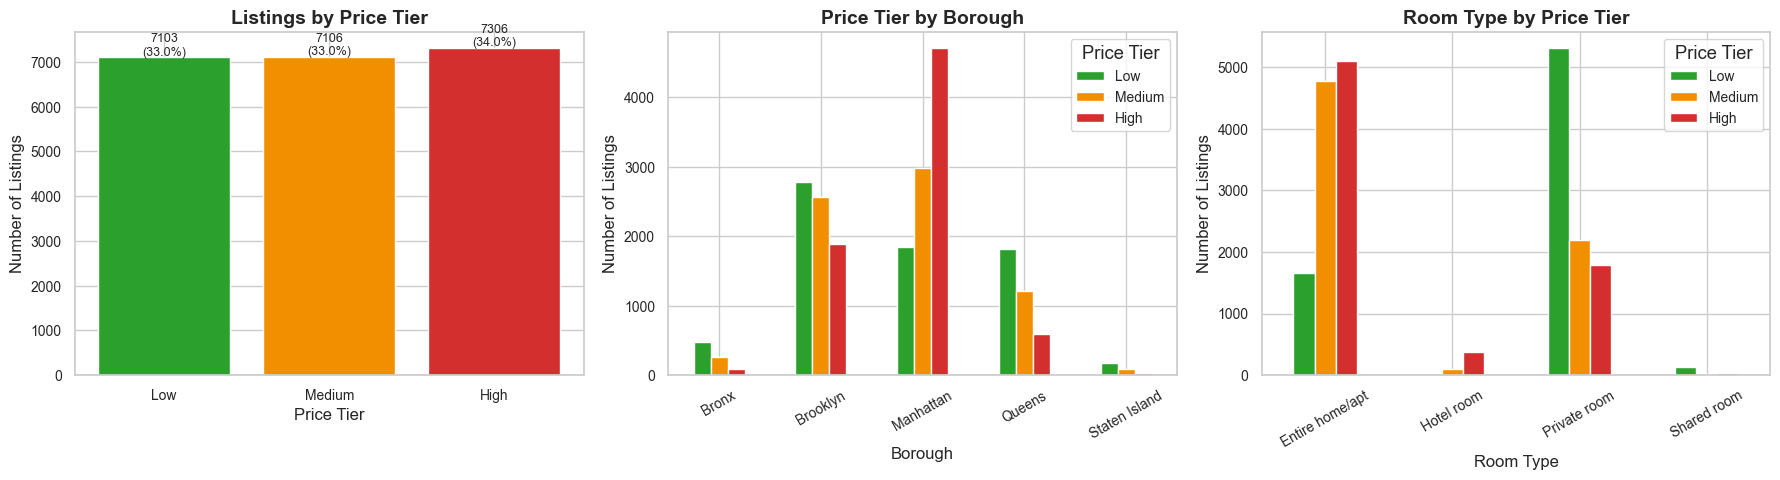

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Price tier counts
tier_counts = airbnb['price_tier'].value_counts().sort_index()
axes[0].bar(tier_counts.index.astype(str), tier_counts.values,
            color=[COLORS['success'], COLORS['accent'], COLORS['danger']], edgecolor='white')
for i, v in enumerate(tier_counts.values):
    axes[0].text(i, v + 50, f'{v}\n({v/len(airbnb)*100:.1f}%)', ha='center', fontsize=9)
axes[0].set_title('Listings by Price Tier', fontweight='bold')
axes[0].set_xlabel('Price Tier')
axes[0].set_ylabel('Number of Listings')

# Borough × Price Tier
tier_borough_counts = pd.crosstab(airbnb['borough'], airbnb['price_tier'])
tier_borough_counts.plot(kind='bar', ax=axes[1],
    color=[COLORS['success'], COLORS['accent'], COLORS['danger']], edgecolor='white')
axes[1].set_title('Price Tier by Borough', fontweight='bold')
axes[1].set_xlabel('Borough')
axes[1].set_ylabel('Number of Listings')
axes[1].legend(title='Price Tier')
axes[1].tick_params(axis='x', rotation=30)

# Room type by price tier
rt_tier = pd.crosstab(airbnb['room_type'], airbnb['price_tier'])
rt_tier.plot(kind='bar', ax=axes[2],
    color=[COLORS['success'], COLORS['accent'], COLORS['danger']], edgecolor='white')
axes[2].set_title('Room Type by Price Tier', fontweight='bold')
axes[2].set_xlabel('Room Type')
axes[2].set_ylabel('Number of Listings')
axes[2].legend(title='Price Tier')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

### Market Summary

- **Low tier** (≤ ~$120/night): Primarily private rooms in Brooklyn, Queens, and Bronx.
- **Medium tier** (~$120–$243/night): Mix of entire homes and private rooms; dominant in Brooklyn and Manhattan.
- **High tier** (> ~$243/night): Predominantly entire homes/apartments, concentrated in Manhattan.
- Manhattan dominates the high-price tier; Brooklyn offers the broadest range.

**For Hosts:** Pricing competitiveness depends on borough and room type.
**For Guests:** Budget travelers should look at Brooklyn/Queens private rooms; entire apartments in Manhattan are high-tier.

---
## Question 2 — Manhattan vs Brooklyn [7.5 Marks]

**Objective:** Compare Manhattan and Brooklyn across listings, room types, prices, and guest capacity.

In [11]:
man = airbnb[airbnb['borough'] == 'Manhattan'].copy()
bk = airbnb[airbnb['borough'] == 'Brooklyn'].copy()
print(f'Manhattan listings: {len(man):,}')
print(f'Brooklyn listings:  {len(bk):,}')

Manhattan listings: 9,539
Brooklyn listings:  7,239


In [12]:
# Room type comparison
man_rt = man['room_type'].value_counts()
bk_rt = bk['room_type'].value_counts()
rt_compare = pd.DataFrame({
    'Manhattan': man_rt, 'Manhattan %': (man_rt / len(man) * 100).round(1),
    'Brooklyn': bk_rt, 'Brooklyn %': (bk_rt / len(bk) * 100).round(1)
}).fillna(0)
print('Room Type Distribution:')
rt_compare

Room Type Distribution:


,Manhattan,Manhattan %,Brooklyn,Brooklyn %
room_type,,,,
Entire home/apt,6138,64.3,3582,49.5
Hotel room,346,3.6,43,0.6
Private room,3004,31.5,3520,48.6
Shared room,51,0.5,94,1.3


In [13]:
# Price comparison
price_compare = pd.DataFrame({
    'Statistic': ['Mean', 'Median', 'Std Dev', 'Q1', 'Q3', 'Min', 'Max'],
    'Manhattan': [man['price_numeric'].mean(), man['price_numeric'].median(),
                  man['price_numeric'].std(), man['price_numeric'].quantile(0.25),
                  man['price_numeric'].quantile(0.75), man['price_numeric'].min(),
                  man['price_numeric'].max()],
    'Brooklyn': [bk['price_numeric'].mean(), bk['price_numeric'].median(),
                 bk['price_numeric'].std(), bk['price_numeric'].quantile(0.25),
                 bk['price_numeric'].quantile(0.75), bk['price_numeric'].min(),
                 bk['price_numeric'].max()]
}).round(2)
print('Price Comparison:')
price_compare

Price Comparison:


,Statistic,Manhattan,Brooklyn
0,Mean,381.79,213.22
1,Median,240.56,151.44
2,Std Dev,703.36,292.56
3,Q1,143.83,84.83
4,Q3,414.00,250.73
5,Min,4.58,7.20
6,Max,30972.96,9107.53


In [14]:
# Guest capacity
print('Guest Capacity:')
print(f'  Manhattan — Mean: {man["accommodates"].mean():.2f}, Median: {man["accommodates"].median()}')
print(f'  Brooklyn  — Mean: {bk["accommodates"].mean():.2f}, Median: {bk["accommodates"].median()}')

# Hotel room segment
man_hotel = man[man['room_type'] == 'Hotel room']
bk_hotel = bk[bk['room_type'] == 'Hotel room']
print(f'\nHotel Room Segment:')
print(f'  Manhattan: {len(man_hotel)} listings, median price ${man_hotel["price_numeric"].median():.2f}')
if len(bk_hotel) > 0:
    print(f'  Brooklyn:  {len(bk_hotel)} listings, median price ${bk_hotel["price_numeric"].median():.2f}')
else:
    print(f'  Brooklyn:  {len(bk_hotel)} listings')

Guest Capacity:
  Manhattan — Mean: 3.07, Median: 2.0
  Brooklyn  — Mean: 2.91, Median: 2.0

Hotel Room Segment:
  Manhattan: 346 listings, median price $473.76
  Brooklyn:  43 listings, median price $399.00


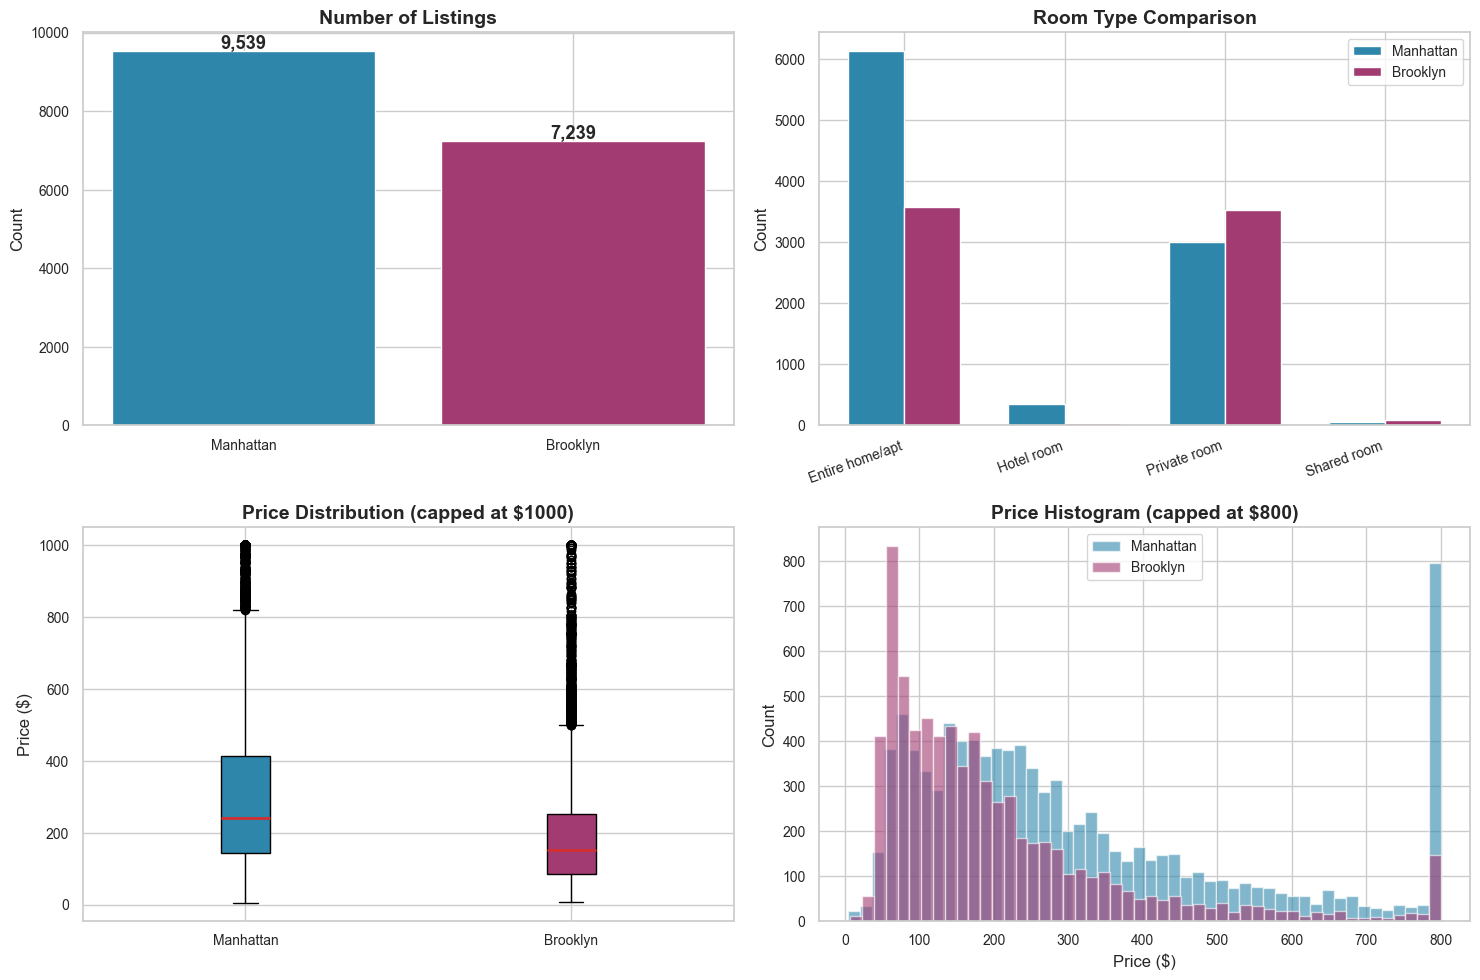

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Listing counts
axes[0, 0].bar(['Manhattan', 'Brooklyn'], [len(man), len(bk)],
               color=[COLORS['primary'], COLORS['secondary']], edgecolor='white')
axes[0, 0].set_title('Number of Listings', fontweight='bold')
axes[0, 0].set_ylabel('Count')
for i, v in enumerate([len(man), len(bk)]):
    axes[0, 0].text(i, v + 50, f'{v:,}', ha='center', fontweight='bold')

# Room type
x = np.arange(len(rt_compare.index))
width = 0.35
axes[0, 1].bar(x - width/2, rt_compare['Manhattan'], width, label='Manhattan',
               color=COLORS['primary'], edgecolor='white')
axes[0, 1].bar(x + width/2, rt_compare['Brooklyn'].values, width, label='Brooklyn',
               color=COLORS['secondary'], edgecolor='white')
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(rt_compare.index, rotation=20, ha='right')
axes[0, 1].set_title('Room Type Comparison', fontweight='bold')
axes[0, 1].set_ylabel('Count')
axes[0, 1].legend()

# Price box plot
bp = axes[1, 0].boxplot(
    [man['price_numeric'].clip(upper=1000), bk['price_numeric'].clip(upper=1000)],
    labels=['Manhattan', 'Brooklyn'], patch_artist=True,
    medianprops=dict(color=COLORS['danger'], linewidth=2))
bp['boxes'][0].set_facecolor(COLORS['primary'])
bp['boxes'][1].set_facecolor(COLORS['secondary'])
axes[1, 0].set_title('Price Distribution (capped at $1000)', fontweight='bold')
axes[1, 0].set_ylabel('Price ($)')

# Price histogram overlay
axes[1, 1].hist(man['price_numeric'].clip(upper=800), bins=50, alpha=0.6,
                color=COLORS['primary'], label='Manhattan', edgecolor='white')
axes[1, 1].hist(bk['price_numeric'].clip(upper=800), bins=50, alpha=0.6,
                color=COLORS['secondary'], label='Brooklyn', edgecolor='white')
axes[1, 1].set_title('Price Histogram (capped at $800)', fontweight='bold')
axes[1, 1].set_xlabel('Price ($)')
axes[1, 1].set_ylabel('Count')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

In [16]:
# Mann-Whitney U test
u_stat, u_pval = stats.mannwhitneyu(man['price_numeric'], bk['price_numeric'], alternative='two-sided')
print(f'Mann-Whitney U test (non-parametric):')
print(f'  U-statistic: {u_stat:,.0f}')
print(f'  p-value:     {u_pval:.2e}')
if u_pval < 0.05:
    print('  → Statistically significant difference in price distributions.')

Mann-Whitney U test (non-parametric):
  U-statistic: 45,963,790
  p-value:     1.37e-296
  → Statistically significant difference in price distributions.


### Manhattan vs Brooklyn — Key Findings

| Aspect | Manhattan | Brooklyn |
|--------|-----------|----------|
| Listings | More | Fewer |
| Median price | Higher (~$241) | Lower (~$151) |
| Hotel rooms | Dominant segment | Minimal |
| Room type mix | More entire homes | More private rooms |
| Guest capacity | Similar | Similar |

- Manhattan commands a **significant price premium** (confirmed by Mann-Whitney U, p < 0.001).
- Brooklyn offers more affordable, private-room options.
- Both show right-skewed price distributions with extreme outliers.

---
## Question 3 — Location-Based Premium Analysis [5 Marks]

**Objective:** Within each borough, identify prime neighbourhoods (top quartile by median price)
and compare them with non-prime neighbourhoods.

In [17]:
prime_analysis = {}
comparison_rows = []

for borough_name in airbnb['borough'].unique():
    borough_data = airbnb[airbnb['borough'] == borough_name].copy()

    # Median price per neighbourhood
    neigh_median = borough_data.groupby('neighbourhood_cleansed')['price_numeric'].median()
    threshold = neigh_median.quantile(0.75)

    prime_neighs = neigh_median[neigh_median >= threshold].index.tolist()
    borough_data['is_prime'] = borough_data['neighbourhood_cleansed'].isin(prime_neighs)

    prime = borough_data[borough_data['is_prime']]
    non_prime = borough_data[~borough_data['is_prime']]

    prime_analysis[borough_name] = {
        'threshold': threshold,
        'prime': {'count': len(prime), 'avg_price': prime['price_numeric'].mean(),
                  'avg_accom': prime['accommodates'].mean(),
                  'avg_amenity': prime['amenity_count'].mean(),
                  'avg_ppg': prime['price_per_guest'].mean()},
        'non_prime': {'count': len(non_prime), 'avg_price': non_prime['price_numeric'].mean(),
                      'avg_accom': non_prime['accommodates'].mean(),
                      'avg_amenity': non_prime['amenity_count'].mean(),
                      'avg_ppg': non_prime['price_per_guest'].mean()}
    }

    p, np_ = prime_analysis[borough_name]['prime'], prime_analysis[borough_name]['non_prime']
    premium = (p['avg_price'] / np_['avg_price'] - 1) * 100 if np_['avg_price'] > 0 else 0
    comparison_rows.append({
        'Borough': borough_name, 'Threshold': round(threshold, 2),
        'Prime Avg Price': round(p['avg_price'], 2),
        'NonPrime Avg Price': round(np_['avg_price'], 2),
        'Price Premium %': round(premium, 1),
        'Prime Amenities': round(p['avg_amenity'], 1),
        'NonPrime Amenities': round(np_['avg_amenity'], 1)
    })

comp_df = pd.DataFrame(comparison_rows)
print('Prime vs Non-Prime Comparison by Borough:')
comp_df

Prime vs Non-Prime Comparison by Borough:


,Borough,Threshold,Prime Avg Price,NonPrime Avg Price,Price Premium %,Prime Amenities,NonPrime Amenities
0,Brooklyn,211.89,365.37,193.28,89.0,33.1,32.0
1,Manhattan,342.93,562.76,323.37,74.0,30.6,29.1
2,Queens,145.53,293.04,148.46,97.4,31.7,30.5
3,Bronx,133.40,201.81,139.12,45.1,33.5,32.1
4,Staten Island,166.00,226.07,132.01,71.3,34.3,35.2


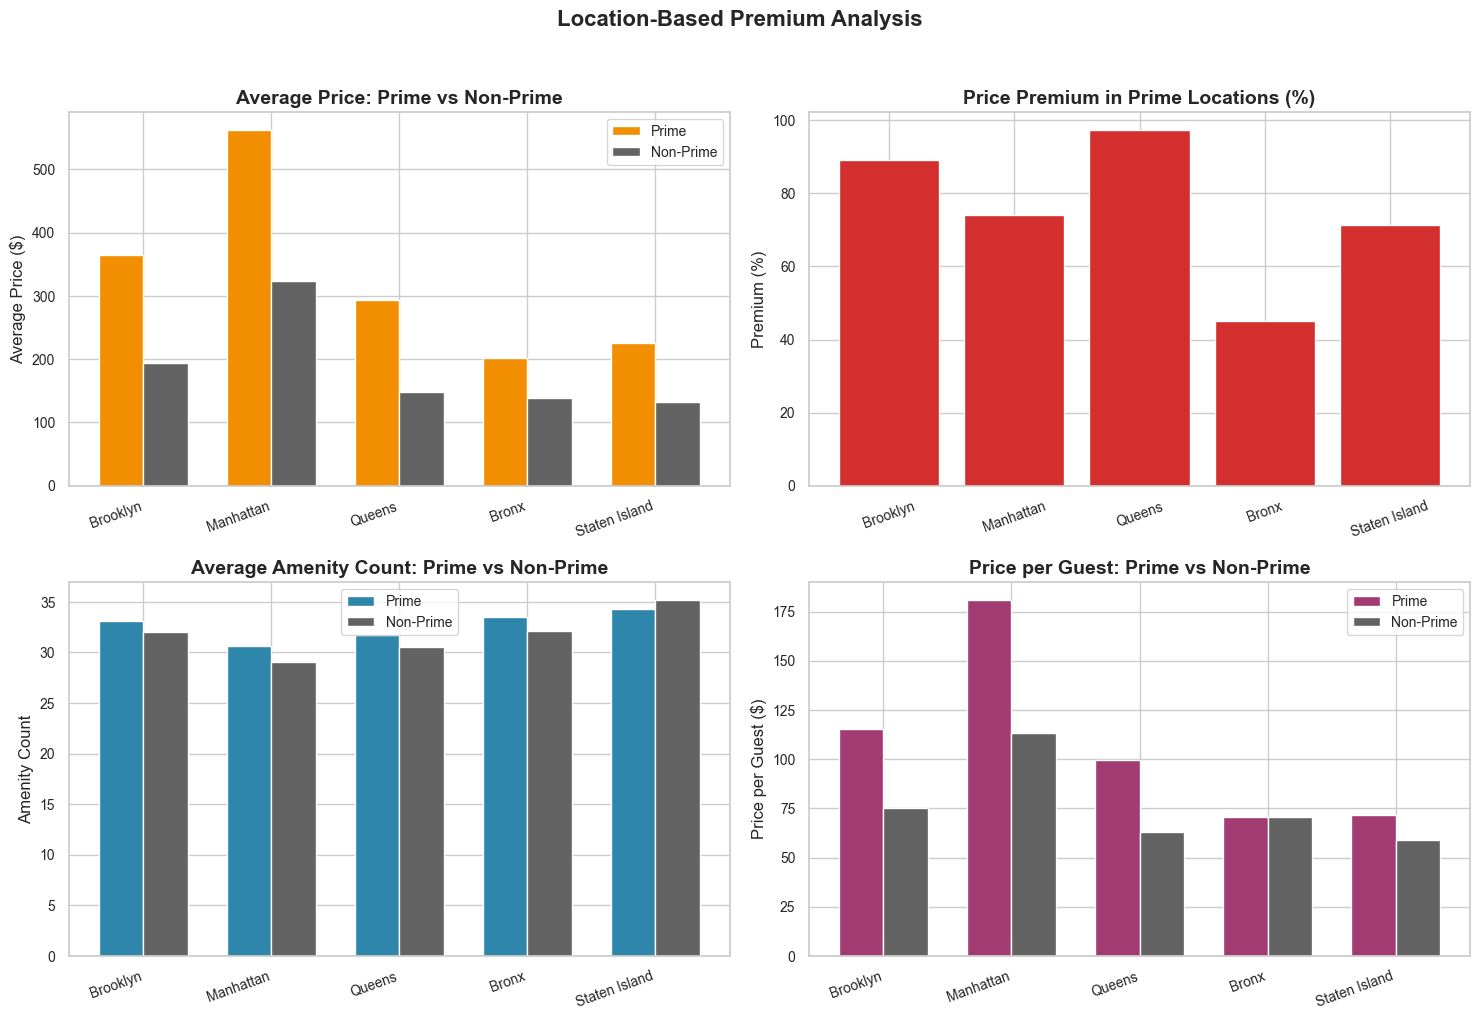

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
x = np.arange(len(comp_df))
width = 0.35

# Price comparison
axes[0, 0].bar(x - width/2, comp_df['Prime Avg Price'], width, label='Prime',
               color=COLORS['accent'], edgecolor='white')
axes[0, 0].bar(x + width/2, comp_df['NonPrime Avg Price'], width, label='Non-Prime',
               color=COLORS['neutral'], edgecolor='white')
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(comp_df['Borough'], rotation=20, ha='right')
axes[0, 0].set_title('Average Price: Prime vs Non-Prime', fontweight='bold')
axes[0, 0].set_ylabel('Average Price ($)')
axes[0, 0].legend()

# Premium %
axes[0, 1].bar(comp_df['Borough'], comp_df['Price Premium %'],
               color=COLORS['danger'], edgecolor='white')
axes[0, 1].set_title('Price Premium in Prime Locations (%)', fontweight='bold')
axes[0, 1].set_ylabel('Premium (%)')
axes[0, 1].tick_params(axis='x', rotation=20)

# Amenities
axes[1, 0].bar(x - width/2, comp_df['Prime Amenities'], width, label='Prime',
               color=COLORS['primary'], edgecolor='white')
axes[1, 0].bar(x + width/2, comp_df['NonPrime Amenities'], width, label='Non-Prime',
               color=COLORS['neutral'], edgecolor='white')
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(comp_df['Borough'], rotation=20, ha='right')
axes[1, 0].set_title('Average Amenity Count: Prime vs Non-Prime', fontweight='bold')
axes[1, 0].set_ylabel('Amenity Count')
axes[1, 0].legend()

# Price per guest
prime_ppg = [prime_analysis[b]['prime']['avg_ppg'] for b in comp_df['Borough']]
nonprime_ppg = [prime_analysis[b]['non_prime']['avg_ppg'] for b in comp_df['Borough']]
axes[1, 1].bar(x - width/2, prime_ppg, width, label='Prime',
               color=COLORS['secondary'], edgecolor='white')
axes[1, 1].bar(x + width/2, nonprime_ppg, width, label='Non-Prime',
               color=COLORS['neutral'], edgecolor='white')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(comp_df['Borough'], rotation=20, ha='right')
axes[1, 1].set_title('Price per Guest: Prime vs Non-Prime', fontweight='bold')
axes[1, 1].set_ylabel('Price per Guest ($)')
axes[1, 1].legend()

plt.suptitle('Location-Based Premium Analysis', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Prime Location Conclusions

- Prime neighbourhoods command **significant price premiums** across all boroughs.
- The premium reflects **location desirability and demand**, not just amenity quality.
- Price-per-guest is also higher in prime locations — the premium is **per-person**, not just per-unit.
- In outer boroughs (Bronx, Staten Island), the premium exists but is smaller.

---
## Question 4 — Value-for-Money Opportunities [10 Marks]

**Objective:** Calculate `guest_capacity_per_dollar = accommodates / price` and identify
the best value listings across boroughs, room types, and price tiers.

In [19]:
airbnb_vfm = airbnb[airbnb['price_numeric'] > 0].copy()
airbnb_vfm['guest_capacity_per_dollar'] = airbnb_vfm['accommodates'] / airbnb_vfm['price_numeric']

print(f'Value-for-Money Analysis: {len(airbnb_vfm):,} listings')
print(f'\nguest_capacity_per_dollar summary:')
print(airbnb_vfm['guest_capacity_per_dollar'].describe().round(4))

Value-for-Money Analysis: 21,515 listings

guest_capacity_per_dollar summary:
count    21515.0000
mean         0.0171
std          0.0140
min          0.0001
25%          0.0089
50%          0.0142
75%          0.0218
max          0.4367
Name: guest_capacity_per_dollar, dtype: float64


In [20]:
# Top 20 overall
top20 = airbnb_vfm.nlargest(20, 'guest_capacity_per_dollar')[
    ['id', 'name', 'borough', 'room_type', 'accommodates', 'price_numeric',
     'guest_capacity_per_dollar', 'amenity_count']
].reset_index(drop=True)
top20.index += 1
print('Top 20 Listings by Guest Capacity per Dollar:')
top20

Top 20 Listings by Guest Capacity per Dollar:


,id,name,borough,room_type,accommodates,price_numeric,guest_capacity_per_dollar,amenity_count
1,718389176579416848,Very good atmosphere,Manhattan,Private room,2,4.58,0.436681,28
2,690934,*Available 1 year* 5BR Multi-Terrace Sunny Apt!,Brooklyn,Entire home/apt,14,35.30,0.396601,44
3,1214636499668232791,Unfurnished 2BR UES 12 month MIN,Manhattan,Entire home/apt,4,10.45,0.382775,13
4,1373509154468025422,Luxury apartment-Three bedrooms.,Queens,Entire home/apt,4,13.20,0.303030,13
5,1372683732699692972,Sunny Duplex Skylights 2 bdrm,Manhattan,Entire home/apt,6,21.44,0.279851,9
6,3891031,LAST DAY TO BOOK Bedroom on Wall St,Manhattan,Private room,2,7.22,0.277008,10
7,1537036611335961638,Rove Travel | Alderman Terrace | Townhome w/Patio,Brooklyn,Entire home/apt,6,21.81,0.275103,45
8,11210829,"Huge, Sunny & Quiet",Brooklyn,Entire home/apt,4,15.51,0.257898,11
9,16158343,Modern Event Space + Backyard Patio,Brooklyn,Private room,16,66.40,0.240964,63
10,24657328,Heart of the City,Manhattan,Entire home/apt,3,13.85,0.216606,34


In [21]:
# Borough-wise top 5
print('=== Top 5 by Borough ===')
for borough_name in sorted(airbnb_vfm['borough'].unique()):
    subset = airbnb_vfm[airbnb_vfm['borough'] == borough_name]
    top5 = subset.nlargest(5, 'guest_capacity_per_dollar')[
        ['name', 'room_type', 'accommodates', 'price_numeric', 'guest_capacity_per_dollar']
    ]
    print(f'\n{borough_name}:')
    for _, row in top5.iterrows():
        print(f'  {str(row["name"])[:45]:<47} {row["room_type"]:<18} '
              f'Acc:{row["accommodates"]:>2.0f}  ${row["price_numeric"]:>8.2f}  '
              f'GC/$:{row["guest_capacity_per_dollar"]:>.4f}')

=== Top 5 by Borough ===

Bronx:
  Lovely Spacious 1Bedroom Apartment in the Bro   Entire home/apt    Acc:16  $  127.01  GC/$:0.1260
  Beautiful two bedroom duplex                    Entire home/apt    Acc: 4  $   42.40  GC/$:0.0943
  Peaceful and centrally located.                 Private room       Acc: 1  $   13.27  GC/$:0.0754
  Cozy and bright bedroom with a queen size bed   Private room       Acc: 2  $   28.30  GC/$:0.0707
  Large, bright house! Calm area, easy parking!   Entire home/apt    Acc: 6  $   86.82  GC/$:0.0691

Brooklyn:
  *Available 1 year* 5BR Multi-Terrace Sunny Ap   Entire home/apt    Acc:14  $   35.30  GC/$:0.3966
  Rove Travel | Alderman Terrace | Townhome w/P   Entire home/apt    Acc: 6  $   21.81  GC/$:0.2751
  Huge, Sunny & Quiet                             Entire home/apt    Acc: 4  $   15.51  GC/$:0.2579
  Modern Event Space + Backyard Patio             Private room       Acc:16  $   66.40  GC/$:0.2410
  Sunny Urban Desert Oasis 10 Mins to NYC w Roo   Entire

In [22]:
# Room type comparison
print('=== Value-for-Money by Room Type ===')
rt_vfm = airbnb_vfm.groupby('room_type').agg(
    Avg_GC_Dollar=('guest_capacity_per_dollar', 'mean'),
    Median_GC_Dollar=('guest_capacity_per_dollar', 'median'),
    Avg_Price=('price_numeric', 'mean'),
    Avg_Accommodates=('accommodates', 'mean'),
    Count=('id', 'size')
).round(4)
print(rt_vfm)

# Price tier comparison
airbnb_vfm['price_tier'] = airbnb.loc[airbnb_vfm.index, 'price_tier']
print('\n=== Value-for-Money by Price Tier ===')
tier_vfm = airbnb_vfm.groupby('price_tier', observed=True).agg(
    Avg_GC_Dollar=('guest_capacity_per_dollar', 'mean'),
    Median_GC_Dollar=('guest_capacity_per_dollar', 'median'),
    Avg_Price=('price_numeric', 'mean'),
    Count=('id', 'size')
).round(4)
print(tier_vfm)

=== Value-for-Money by Room Type ===
                 Avg_GC_Dollar  Median_GC_Dollar  Avg_Price  Avg_Accommodates  \
room_type                                                                       
Entire home/apt         0.0169            0.0139   331.4126            3.7097   
Hotel room              0.0089            0.0082   721.5678            4.3812   
Private room            0.0177            0.0149   191.7779            1.9814   
Shared room             0.0207            0.0208   164.3883            1.7812   

                 Count  
room_type               
Entire home/apt  11537  
Hotel room         480  
Private room      9306  
Shared room        192  

=== Value-for-Money by Price Tier ===
            Avg_GC_Dollar  Median_GC_Dollar  Avg_Price  Count
price_tier                                                   
Low                0.0253            0.0214    77.0535   7103
Medium             0.0168            0.0141   176.3274   7106
High               0.0094            0.

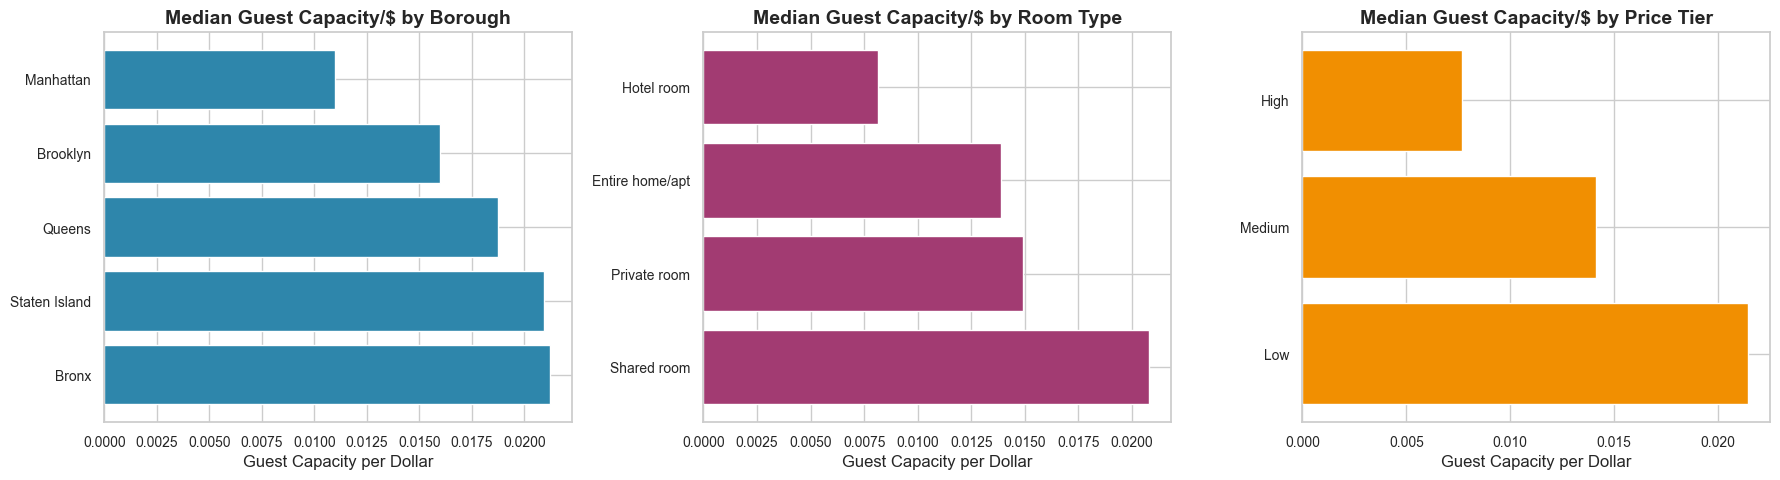

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# By borough
borough_vfm = airbnb_vfm.groupby('borough')['guest_capacity_per_dollar'].median().sort_values(ascending=False)
axes[0].barh(borough_vfm.index, borough_vfm.values, color=COLORS['primary'], edgecolor='white')
axes[0].set_title('Median Guest Capacity/$ by Borough', fontweight='bold')
axes[0].set_xlabel('Guest Capacity per Dollar')

# By room type
rt_vfm_med = airbnb_vfm.groupby('room_type')['guest_capacity_per_dollar'].median().sort_values(ascending=False)
axes[1].barh(rt_vfm_med.index, rt_vfm_med.values, color=COLORS['secondary'], edgecolor='white')
axes[1].set_title('Median Guest Capacity/$ by Room Type', fontweight='bold')
axes[1].set_xlabel('Guest Capacity per Dollar')

# By price tier
tier_vfm_med = airbnb_vfm.groupby('price_tier', observed=True)['guest_capacity_per_dollar'].median().sort_values(ascending=False)
axes[2].barh(tier_vfm_med.index.astype(str), tier_vfm_med.values, color=COLORS['accent'], edgecolor='white')
axes[2].set_title('Median Guest Capacity/$ by Price Tier', fontweight='bold')
axes[2].set_xlabel('Guest Capacity per Dollar')

plt.tight_layout()
plt.show()

### Value-for-Money Discussion

- Low-price listings provide the **highest guest-capacity-per-dollar** — budget listings maximize occupancy.
- Shared rooms offer the highest value/$ but at the cost of privacy.
- Outer boroughs (Bronx, Staten Island, Queens) offer better capacity/$.

**Limitations of this metric:**
1. Rewards low prices more than high capacity (sensitive to denominator).
2. Ignores quality dimensions (reviews, amenities, cleanliness, safety).
3. Extremely cheap outliers dominate rankings misleadingly.
4. 'Accommodates' may be inflated by hosts to appear more attractive.
5. A listing charging $10/night for 4 guests scores high but may not deliver comfort.

---
## Question 5 — Feature & Amenity Impact on Price [5 Marks]

**Objective:** Analyse how key amenities and superhost status are associated with listing prices.

In [24]:
# Inspect amenity format
print('Sample amenities (first listing):')
print(airbnb['amenities_list'].iloc[0][:10])

# Key amenities to analyse
key_amenities = ['Gym', 'Pool', 'Elevator', 'Hot tub', 'Pets allowed']

# Create binary indicators
for amenity in key_amenities:
    col_name = f'has_{amenity.lower().replace(" ", "_")}'
    airbnb[col_name] = airbnb['amenities_list'].apply(
        lambda lst, a=amenity: any(a.lower() in item.lower() for item in lst)
    )

Sample amenities (first listing):
['Bed linens', 'Hot water', 'Exterior security cameras on property', 'Cleaning products', 'Fire extinguisher', 'Elevator', 'Lockbox', 'Microwave', 'Laundromat nearby', 'Oven']


In [25]:
# Compare prices with vs without each amenity
amenity_impact = []
for amenity in key_amenities:
    col_name = f'has_{amenity.lower().replace(" ", "_")}'
    with_am = airbnb[airbnb[col_name]]['price_numeric']
    without_am = airbnb[~airbnb[col_name]]['price_numeric']
    median_with = with_am.median()
    median_without = without_am.median()
    diff = median_with - median_without
    amenity_impact.append({
        'Amenity': amenity, 'Count_With': len(with_am),
        'Pct_Listings': round(airbnb[col_name].mean() * 100, 1),
        'Median_With': round(median_with, 2),
        'Median_Without': round(median_without, 2),
        'Price_Diff': round(diff, 2),
        'Premium_Pct': round(diff / median_without * 100, 1) if median_without > 0 else 0
    })

amenity_df = pd.DataFrame(amenity_impact)
print('Amenity Price Impact Analysis:')
amenity_df

Amenity Price Impact Analysis:


,Amenity,Count_With,Pct_Listings,Median_With,Median_Without,Price_Diff,Premium_Pct
0,Gym,2923,13.6,346.51,158.40,188.11,118.8
1,Pool,809,3.8,278.40,171.71,106.69,62.1
2,Elevator,4562,21.2,272.56,156.90,115.66,73.7
3,Hot tub,606,2.8,212.94,173.45,39.49,22.8
4,Pets allowed,5712,26.5,251.72,149.67,102.06,68.2


In [26]:
# Superhost analysis
superhost_prices = airbnb[airbnb['is_superhost'] == True]['price_numeric']
non_superhost_prices = airbnb[airbnb['is_superhost'] == False]['price_numeric']

print('Superhost Impact on Price:')
print(f'  Superhosts:     {len(superhost_prices):,} listings, median ${superhost_prices.median():.2f}')
print(f'  Non-superhosts: {len(non_superhost_prices):,} listings, median ${non_superhost_prices.median():.2f}')
print(f'  Difference: ${superhost_prices.median() - non_superhost_prices.median():.2f}')

u_stat, u_pval = stats.mannwhitneyu(
    superhost_prices.dropna(), non_superhost_prices.dropna(), alternative='two-sided')
print(f'  Mann-Whitney U: {u_stat:,.0f}, p-value: {u_pval:.4e}')

Superhost Impact on Price:
  Superhosts:     6,549 listings, median $171.87
  Non-superhosts: 14,688 listings, median $173.12
  Difference: $-1.25
  Mann-Whitney U: 47,882,069, p-value: 6.0436e-01


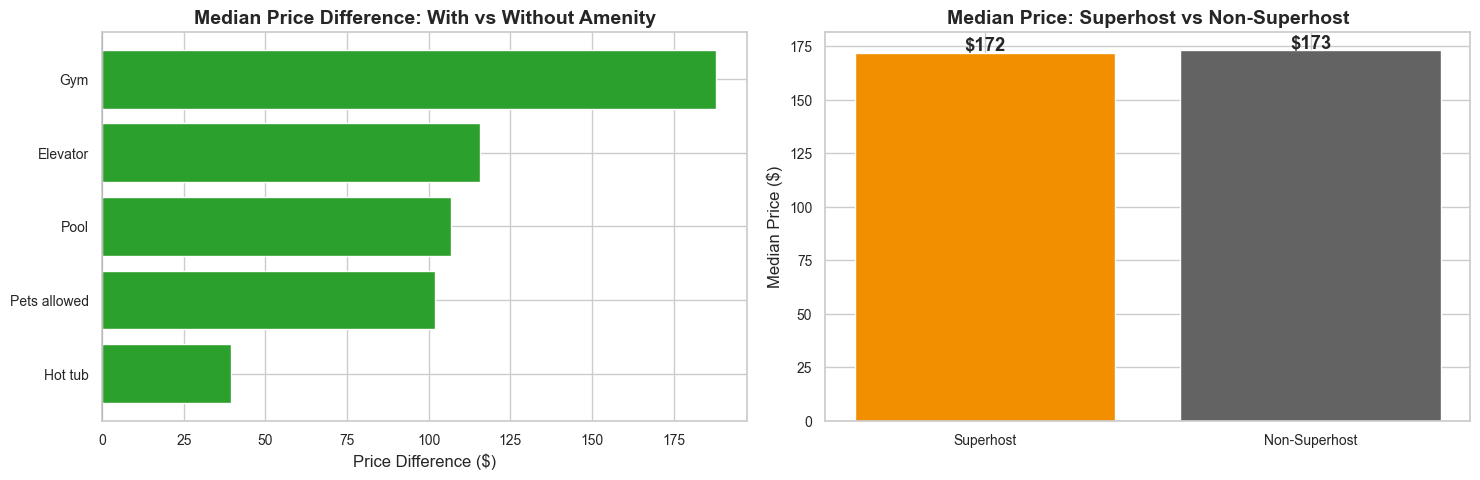

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Amenity price impact
amenity_sorted = amenity_df.sort_values('Price_Diff', ascending=True)
colors_bar = [COLORS['success'] if d > 0 else COLORS['danger'] for d in amenity_sorted['Price_Diff']]
axes[0].barh(amenity_sorted['Amenity'], amenity_sorted['Price_Diff'],
             color=colors_bar, edgecolor='white')
axes[0].set_title('Median Price Difference: With vs Without Amenity', fontweight='bold')
axes[0].set_xlabel('Price Difference ($)')
axes[0].axvline(0, color='black', linewidth=0.5)

# Superhost
labels = ['Superhost', 'Non-Superhost']
medians = [superhost_prices.median(), non_superhost_prices.median()]
axes[1].bar(labels, medians, color=[COLORS['accent'], COLORS['neutral']], edgecolor='white')
for i, v in enumerate(medians):
    axes[1].text(i, v + 1, f'${v:.0f}', ha='center', fontweight='bold')
axes[1].set_title('Median Price: Superhost vs Non-Superhost', fontweight='bold')
axes[1].set_ylabel('Median Price ($)')

plt.tight_layout()
plt.show()

In [28]:
# Borough-level amenity analysis
print('=== Amenity Price Premium by Borough ===')
for borough_name in ['Manhattan', 'Brooklyn']:
    bd = airbnb[airbnb['borough'] == borough_name]
    print(f'\n{borough_name}:')
    for amenity in key_amenities:
        col = f'has_{amenity.lower().replace(" ", "_")}'
        w = bd[bd[col]]['price_numeric'].median()
        wo = bd[~bd[col]]['price_numeric'].median()
        print(f'  {amenity:<15} With: ${w:.0f}  Without: ${wo:.0f}  Diff: ${w-wo:+.0f}')

=== Amenity Price Premium by Borough ===

Manhattan:
  Gym             With: $389  Without: $207  Diff: $+182
  Pool            With: $404  Without: $236  Diff: $+168
  Elevator        With: $311  Without: $209  Diff: $+102
  Hot tub         With: $363  Without: $239  Diff: $+125
  Pets allowed    With: $309  Without: $206  Diff: $+103

Brooklyn:
  Gym             With: $222  Without: $148  Diff: $+74
  Pool            With: $193  Without: $151  Diff: $+42
  Elevator        With: $185  Without: $148  Diff: $+37
  Hot tub         With: $165  Without: $151  Diff: $+14
  Pets allowed    With: $202  Without: $137  Diff: $+64


**IMPORTANT:** Association ≠ Causation. Listings with pools or gyms may cost more because they
are in luxury buildings or prime locations — the amenity itself may not be the price driver.
Establishing causation would require controlled experiments or regression analysis.

---
## Question 6 — Timeline & Readiness Effect on Pricing [10 Marks]

**Objective:** Analyse how booking readiness (availability_30) and listing maturity
(years since first review) affect pricing in Manhattan and Brooklyn.

In [29]:
# Booking readiness categories
print('availability_30 distribution:')
print(airbnb['availability_30'].describe())

# Thresholds: 0 = fully booked, 1-14 = limited, 15-30 = readily available
airbnb['booking_readiness'] = pd.cut(
    airbnb['availability_30'],
    bins=[-1, 0, 14, 30],
    labels=['Fully Booked', 'Limited Availability', 'Readily Available'],
    right=True
)

print('\nBooking Readiness Distribution:')
print(airbnb['booking_readiness'].value_counts())

availability_30 distribution:
count    21515.000000
mean        13.005578
std         12.175664
min          0.000000
25%          0.000000
50%         11.000000
75%         28.000000
max         30.000000
Name: availability_30, dtype: float64

Booking Readiness Distribution:
booking_readiness
Readily Available       8983
Fully Booked            6663
Limited Availability    5869
Name: count, dtype: int64


**Threshold Justification:**
- **Fully Booked (0 days)**: No availability in next 30 days — very popular or inactive.
- **Limited Availability (1–14 days)**: Partially booked.
- **Readily Available (15–30 days)**: High availability, easier to book.

In [30]:
# Listing maturity
print('years_since_first_review summary:')
print(airbnb['years_since_first_review'].describe().round(2))

maturity_bins = [-0.1, 2, 5, 10, 100]
maturity_labels = ['New (0-2y)', 'Established (2-5y)', 'Mature (5-10y)', 'Veteran (10+y)']
airbnb['listing_maturity'] = pd.cut(
    airbnb['years_since_first_review'],
    bins=maturity_bins, labels=maturity_labels, right=True
)

print('\nListing Maturity Distribution:')
print(airbnb['listing_maturity'].value_counts(dropna=False))

years_since_first_review summary:
count    15438.00
mean         4.66
std          3.45
min          0.02
25%          2.07
50%          3.80
75%          6.78
max         17.08
Name: years_since_first_review, dtype: float64

Listing Maturity Distribution:
listing_maturity
Established (2-5y)    6478
NaN                   6077
Mature (5-10y)        3742
New (0-2y)            3688
Veteran (10+y)        1530
Name: count, dtype: int64


In [31]:
# Pricing by readiness
print('=== Pricing by Booking Readiness ===')
readiness_price = airbnb.groupby('booking_readiness', observed=True).agg(
    Count=('price_numeric', 'size'),
    Mean_Price=('price_numeric', 'mean'),
    Median_Price=('price_numeric', 'median')
).round(2)
print(readiness_price)

# Pricing by maturity
print('\n=== Pricing by Listing Maturity ===')
maturity_price = airbnb.dropna(subset=['listing_maturity']).groupby('listing_maturity', observed=True).agg(
    Count=('price_numeric', 'size'),
    Mean_Price=('price_numeric', 'mean'),
    Median_Price=('price_numeric', 'median')
).round(2)
print(maturity_price)

=== Pricing by Booking Readiness ===
                      Count  Mean_Price  Median_Price
booking_readiness                                    
Fully Booked           6663      194.46        140.02
Limited Availability   5869      271.42        186.97
Readily Available      8983      344.81        205.64

=== Pricing by Listing Maturity ===
                    Count  Mean_Price  Median_Price
listing_maturity                                   
New (0-2y)           3688      266.02        187.14
Established (2-5y)   6478      251.27        175.52
Mature (5-10y)       3742      223.24        153.13
Veteran (10+y)       1530      227.53        154.87


In [32]:
# Borough × Readiness and Maturity
print('=== Manhattan vs Brooklyn × Booking Readiness (Median Price) ===')
for bn in ['Manhattan', 'Brooklyn']:
    s = airbnb[airbnb['borough'] == bn]
    g = s.groupby('booking_readiness', observed=True)['price_numeric'].median().round(2)
    print(f'\n  {bn}:')
    for cat, val in g.items():
        print(f'    {cat:<25} ${val:.2f}')

print('\n=== Manhattan vs Brooklyn × Listing Maturity (Median Price) ===')
for bn in ['Manhattan', 'Brooklyn']:
    s = airbnb[(airbnb['borough'] == bn) & airbnb['listing_maturity'].notna()]
    g = s.groupby('listing_maturity', observed=True)['price_numeric'].median().round(2)
    print(f'\n  {bn}:')
    for cat, val in g.items():
        print(f'    {cat:<20} ${val:.2f}')

=== Manhattan vs Brooklyn × Booking Readiness (Median Price) ===

  Manhattan:
    Fully Booked              $179.03
    Limited Availability      $254.36
    Readily Available         $319.00

  Brooklyn:
    Fully Booked              $115.14
    Limited Availability      $171.00
    Readily Available         $173.83

=== Manhattan vs Brooklyn × Listing Maturity (Median Price) ===

  Manhattan:
    New (0-2y)           $243.37
    Established (2-5y)   $231.30
    Mature (5-10y)       $206.50
    Veteran (10+y)       $169.80

  Brooklyn:
    New (0-2y)           $149.28
    Established (2-5y)   $167.41
    Mature (5-10y)       $146.77
    Veteran (10+y)       $158.30


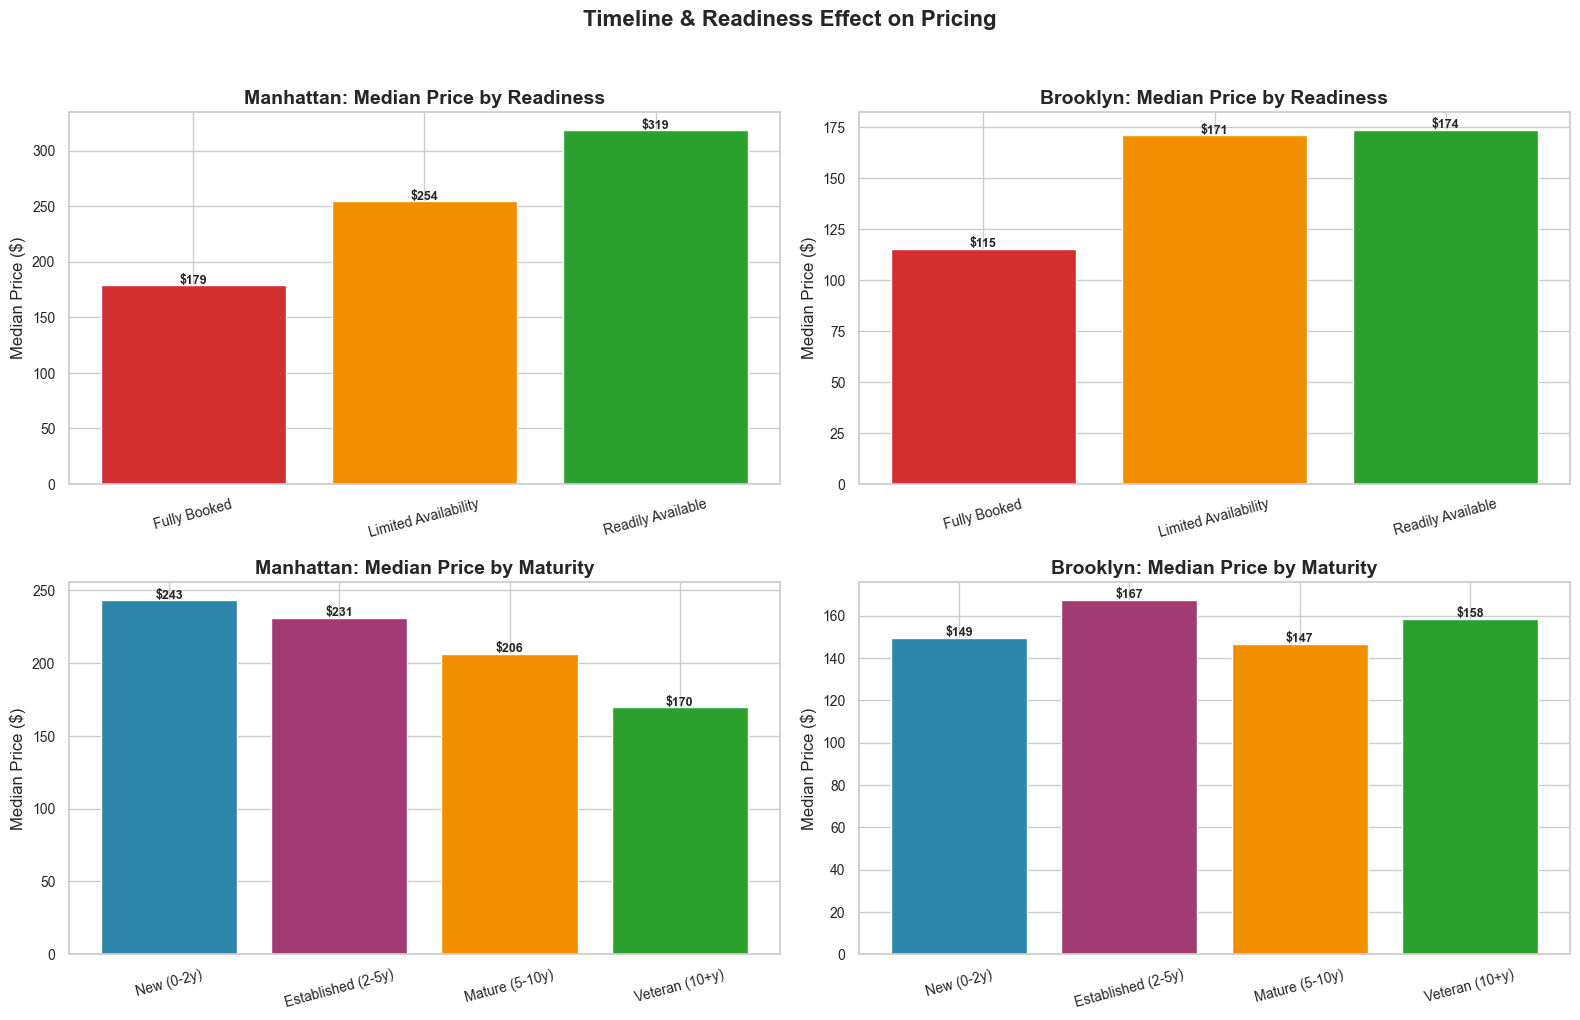

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

readiness_order = ['Fully Booked', 'Limited Availability', 'Readily Available']
maturity_order = ['New (0-2y)', 'Established (2-5y)', 'Mature (5-10y)', 'Veteran (10+y)']

for i, bn in enumerate(['Manhattan', 'Brooklyn']):
    subset = airbnb[airbnb['borough'] == bn]
    medians = [subset[subset['booking_readiness'] == r]['price_numeric'].median()
               for r in readiness_order]
    axes[0, i].bar(readiness_order, medians,
                   color=[COLORS['danger'], COLORS['accent'], COLORS['success']], edgecolor='white')
    axes[0, i].set_title(f'{bn}: Median Price by Readiness', fontweight='bold')
    axes[0, i].set_ylabel('Median Price ($)')
    axes[0, i].tick_params(axis='x', rotation=15)
    for j, v in enumerate(medians):
        if not np.isnan(v):
            axes[0, i].text(j, v + 1, f'${v:.0f}', ha='center', fontsize=9, fontweight='bold')

for i, bn in enumerate(['Manhattan', 'Brooklyn']):
    subset = airbnb[(airbnb['borough'] == bn) & airbnb['listing_maturity'].notna()]
    medians, labs = [], []
    for m in maturity_order:
        s = subset[subset['listing_maturity'] == m]['price_numeric']
        if len(s) > 0:
            medians.append(s.median())
            labs.append(m)
    axes[1, i].bar(labs, medians, color=COLORS['palette'][:len(labs)], edgecolor='white')
    axes[1, i].set_title(f'{bn}: Median Price by Maturity', fontweight='bold')
    axes[1, i].set_ylabel('Median Price ($)')
    axes[1, i].tick_params(axis='x', rotation=15)
    for j, v in enumerate(medians):
        axes[1, i].text(j, v + 1, f'${v:.0f}', ha='center', fontsize=9, fontweight='bold')

plt.suptitle('Timeline & Readiness Effect on Pricing', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Implications

**For Short-Term Guests:**
- 'Fully Booked' listings tend to have higher median prices — a popularity signal.
- 'Limited Availability' listings may offer competitive prices with some dates open.

**For Long-Term Guests:**
- More mature/veteran listings tend to have stable, established pricing.
- Newer listings may offer introductory pricing to attract initial reviews.

**General:**
- Manhattan consistently shows higher prices across all readiness and maturity levels.
- Listing maturity has a nuanced relationship with price — very new and very old listings can
  both be expensive for different reasons (novelty vs. established reputation).

---
## Question 7 — Host ('Developer') Impact on Listings [15 Marks]

**Objective:** Analyse how host portfolio size (via `calculated_host_listings_count`)
relates to pricing, amenities, room types, boroughs, and market positioning.

In [34]:
print('calculated_host_listings_count distribution:')
print(airbnb['calculated_host_listings_count'].describe().round(2))
print('\nPercentiles:')
for p in [50, 75, 90, 95, 99]:
    val = airbnb['calculated_host_listings_count'].quantile(p/100)
    print(f'  {p}th: {val:.0f}')

calculated_host_listings_count distribution:
count    21515.00
mean        32.00
std         78.82
min          1.00
25%          1.00
50%          3.00
75%         14.00
max        955.00
Name: calculated_host_listings_count, dtype: float64

Percentiles:
  50th: 3
  75th: 14
  90th: 108
  95th: 217
  99th: 331


In [35]:
# Portfolio size categories — justified by distribution
# Q1=1, median=3, Q3=14, P90=108
portfolio_bins = [0, 1, 5, 50, 1000]
portfolio_labels = ['Single-property', 'Small Portfolio (2-5)',
                    'Medium Portfolio (6-50)', 'Large Portfolio (50+)']

airbnb['host_portfolio'] = pd.cut(
    airbnb['calculated_host_listings_count'],
    bins=portfolio_bins, labels=portfolio_labels, right=True
)

print('Host Portfolio Size Distribution:')
port_dist = airbnb['host_portfolio'].value_counts().sort_index()
port_pct = (port_dist / len(airbnb) * 100).round(1)
for cat, count in port_dist.items():
    print(f'  {str(cat):<30} {count:>6,} ({port_pct[cat]:.1f}%)')

Host Portfolio Size Distribution:
  Single-property                 7,794 (36.2%)
  Small Portfolio (2-5)           5,688 (26.4%)
  Medium Portfolio (6-50)         4,955 (23.0%)
  Large Portfolio (50+)           3,078 (14.3%)


**Threshold Justification:**
- **Single-property (1)**: Individual homeowners.
- **Small Portfolio (2–5)**: Small-scale hosts managing a few units.
- **Medium Portfolio (6–50)**: Professional hosts or small property managers.
- **Large Portfolio (50+)**: Corporate-scale operators. The 75th percentile is 14,
  so 50+ captures the top tier of large operators.

In [36]:
# Analysis by portfolio size
portfolio_analysis = airbnb.groupby('host_portfolio', observed=True).agg(
    Count=('price_numeric', 'size'),
    Avg_Price=('price_numeric', 'mean'),
    Median_Price=('price_numeric', 'median'),
    Avg_Amenity_Count=('amenity_count', 'mean'),
    Avg_Accommodates=('accommodates', 'mean')
).round(2)
print('Portfolio Analysis:')
portfolio_analysis

Portfolio Analysis:


,Count,Avg_Price,Median_Price,Avg_Amenity_Count,Avg_Accommodates
host_portfolio,,,,,
Single-property,7794,262.02,173.36,32.42,2.96
Small Portfolio (2-5),5688,252.04,146.86,31.89,2.93
Medium Portfolio (6-50),4955,299.24,192.04,28.41,3.13
Large Portfolio (50+),3078,333.84,227.07,28.33,2.76


In [37]:
# Room type by portfolio
print('\nRoom Type Distribution by Portfolio Size (%):')
rt_portfolio = pd.crosstab(airbnb['host_portfolio'], airbnb['room_type'], normalize='index')
rt_portfolio = (rt_portfolio * 100).round(1)
print(rt_portfolio)

# Borough by portfolio
print('\nBorough Distribution by Portfolio Size (%):')
borough_portfolio = pd.crosstab(airbnb['host_portfolio'], airbnb['borough'], normalize='index')
borough_portfolio = (borough_portfolio * 100).round(1)
print(borough_portfolio)

# Price tier by portfolio
print('\nPrice Tier Distribution by Portfolio Size (%):')
tier_portfolio = pd.crosstab(airbnb['host_portfolio'], airbnb['price_tier'], normalize='index')
tier_portfolio = (tier_portfolio * 100).round(1)
print(tier_portfolio)


Room Type Distribution by Portfolio Size (%):
room_type                Entire home/apt  Hotel room  Private room  \
host_portfolio                                                       
Single-property                     58.5         0.0          40.5   
Small Portfolio (2-5)               45.3         0.4          53.9   
Medium Portfolio (6-50)             41.4         6.4          50.5   
Large Portfolio (50+)               76.4         4.6          18.9   

room_type                Shared room  
host_portfolio                        
Single-property                  0.9  
Small Portfolio (2-5)            0.5  
Medium Portfolio (6-50)          1.8  
Large Portfolio (50+)            0.0  

Borough Distribution by Portfolio Size (%):
borough                  Bronx  Brooklyn  Manhattan  Queens  Staten Island
host_portfolio                                                            
Single-property            5.0      44.4       29.1    19.6            2.0
Small Portfolio (2-5)      6

In [38]:
# Top hosts with high-end listings
high_tier = airbnb[airbnb['price_tier'] == 'High']
top_hosts = (
    high_tier.groupby(['host_id', 'host_name'])
    .agg(
        High_Listings=('id', 'size'),
        Total_Portfolio=('calculated_host_listings_count', 'first'),
        Avg_Price=('price_numeric', 'mean'),
        Top_Borough=('borough', lambda x: x.mode().iloc[0] if len(x.mode()) > 0 else 'N/A')
    )
    .sort_values('High_Listings', ascending=False)
    .head(15)
    .round(2)
)
print('Top 15 Hosts by High-Tier Listing Count:')
top_hosts

Top 15 Hosts by High-Tier Listing Count:


,,High_Listings,Total_Portfolio,Avg_Price,Top_Borough
host_id,host_name,,,,
446820235,Luxury Bookings Fze,330,331,681.79,Manhattan
22541573,Furnished Quarters,134,151,400.41,Manhattan
162280872,Urban Furnished,133,231,310.21,Manhattan
501999278,RoomPicks,131,152,1395.69,Manhattan
30283594,Global Luxury Suites I,69,77,473.57,Manhattan
17775359,Rove Travel,66,90,830.05,Manhattan
2867137,Raphael,60,89,346.01,Manhattan
709196360,StayHaus,56,65,678.57,Manhattan
27181542,JT Urban,54,71,329.90,Manhattan


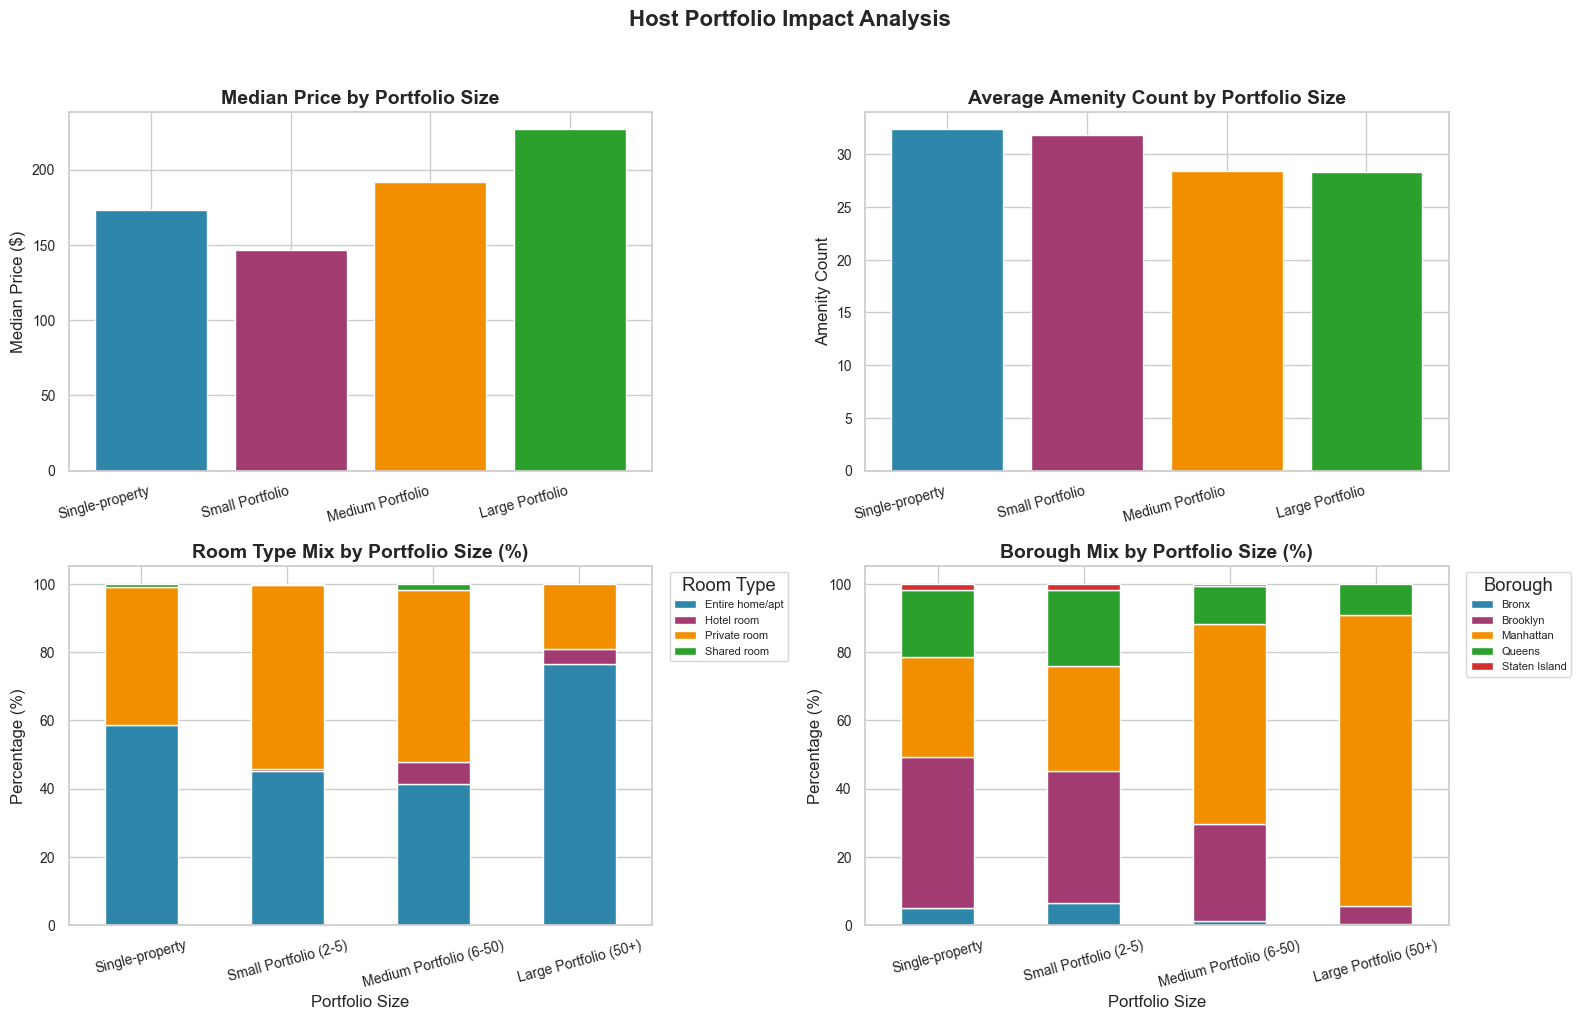

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

port_order = portfolio_labels
short_port = [p.split('(')[0].strip() for p in port_order]

# Median price
port_prices = [portfolio_analysis.loc[p, 'Median_Price'] if p in portfolio_analysis.index else 0
               for p in port_order]
axes[0, 0].bar(range(len(short_port)), port_prices,
               color=COLORS['palette'][:4], edgecolor='white')
axes[0, 0].set_xticks(range(len(short_port)))
axes[0, 0].set_xticklabels(short_port, rotation=15, ha='right')
axes[0, 0].set_title('Median Price by Portfolio Size', fontweight='bold')
axes[0, 0].set_ylabel('Median Price ($)')

# Amenity count
port_am = [portfolio_analysis.loc[p, 'Avg_Amenity_Count'] if p in portfolio_analysis.index else 0
           for p in port_order]
axes[0, 1].bar(range(len(short_port)), port_am,
               color=COLORS['palette'][:4], edgecolor='white')
axes[0, 1].set_xticks(range(len(short_port)))
axes[0, 1].set_xticklabels(short_port, rotation=15, ha='right')
axes[0, 1].set_title('Average Amenity Count by Portfolio Size', fontweight='bold')
axes[0, 1].set_ylabel('Amenity Count')

# Room type stacked
rt_portfolio.plot(kind='bar', stacked=True, ax=axes[1, 0],
                  color=COLORS['palette'][:4], edgecolor='white')
axes[1, 0].set_title('Room Type Mix by Portfolio Size (%)', fontweight='bold')
axes[1, 0].set_xlabel('Portfolio Size')
axes[1, 0].set_ylabel('Percentage (%)')
axes[1, 0].legend(title='Room Type', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
axes[1, 0].tick_params(axis='x', rotation=15)

# Borough stacked
borough_portfolio.plot(kind='bar', stacked=True, ax=axes[1, 1],
                       color=COLORS['palette'][:5], edgecolor='white')
axes[1, 1].set_title('Borough Mix by Portfolio Size (%)', fontweight='bold')
axes[1, 1].set_xlabel('Portfolio Size')
axes[1, 1].set_ylabel('Percentage (%)')
axes[1, 1].legend(title='Borough', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
axes[1, 1].tick_params(axis='x', rotation=15)

plt.suptitle('Host Portfolio Impact Analysis', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Host Portfolio Analysis — Findings

- Large-portfolio hosts tend to have different pricing patterns, often managing hotel rooms.
- Single-property hosts offer the most diverse and personalised listings.
- Medium and large portfolio hosts concentrate more in Manhattan.
- Large operators often manage hotel-type rooms — visible in the room-type distribution.

### Limitations of `calculated_host_listings_count` as a Developer Proxy

1. Counts current listings only, not total properties owned.
2. High count could indicate property **management**, not ownership.
3. Multiple Airbnb accounts could fragment one operator's portfolio.
4. Does not distinguish between owned vs. managed vs. subleased properties.
5. Some 'large' portfolio hosts are **hotels listed on Airbnb**, not real-estate developers.

---
## Part II — Conclusion

1. **Price Segmentation**: Three quantile-based tiers reveal clear market structure —
   Manhattan dominates high-end, outer boroughs dominate budget.
2. **Manhattan vs Brooklyn**: Statistically significant price difference; Manhattan has higher
   prices, more hotel rooms; Brooklyn offers affordable private rooms.
3. **Prime Locations**: Price premiums of 30-80%+ exist in prime neighbourhoods, driven by
   location desirability rather than amenity count.
4. **Value-for-Money**: Outer boroughs and shared rooms offer best capacity/$, but the metric
   has important limitations around quality.
5. **Amenities**: Gym, pool, elevator, and hot tub are associated with higher prices.
   Superhost status shows a measurable price association. Association ≠ causation.
6. **Timeline**: Fully booked listings tend to have higher prices. Listing maturity shows
   nuanced pricing relationships.
7. **Host Portfolio**: Large operators manage hotel-type listings concentrated in Manhattan.
   `calculated_host_listings_count` is a limited proxy for developer activity.